In [1]:
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

In [2]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [3]:
print(device)

cuda:0


In [4]:
from fastai.vision.all import *

In [8]:
from pathlib import Path

root = Path('/kaggle/input')
for path in root.rglob('final'):
    if path.is_dir():
        source = path

print(source)

/kaggle/input/datasets/morsalinantor/aloe-vera-leaf-disease-detection-dataset/Aloe vera leaf disease detection dataset/final


In [ ]:
destination = Path('/kaggle/working/main')

image_files = get_image_files(source)
resize = Resize(224, method=ResizeMethod.Squish)


for image_file in progress_bar(image_files):
    image = PILImage.create(image_file)
    image = resize(image)

    save_path = destination / image_file.relative_to(source)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    image.save(save_path)


<div><progress max="2500" value="2500"></progress> 100.00% [2500/2500 05:17&lt;00:00]</div>

In [13]:
from torchvision.datasets import ImageFolder

dataset = ImageFolder(root = destination)

print("Classes : ", dataset.classes)
print("Class Index : ", dataset.class_to_idx)
print("Number of Images : ", len(dataset))

Classes :  ['Aloe Rust', 'Anthracnose', 'Healthy', 'Leaf Spot', 'Sunburn']
Class Index :  {'Aloe Rust': 0, 'Anthracnose': 1, 'Healthy': 2, 'Leaf Spot': 3, 'Sunburn': 4}
Number of Images :  2500


In [11]:
len(dataset.targets)

2500

In [14]:
freq = {}
for class_name in dataset.classes:
    class_idx = dataset.class_to_idx[class_name]
    img_count = dataset.targets.count(class_idx)
    freq[class_name] = img_count

print(freq)

{'Aloe Rust': 210, 'Anthracnose': 500, 'Healthy': 780, 'Leaf Spot': 500, 'Sunburn': 510}


In [15]:
train_indices, temp_indices = train_test_split(
    range(len(dataset)),
    train_size = 0.7,
    stratify = dataset.targets,
    random_state = 68
)

print(len(train_indices))
print(len(temp_indices))

1750
750


In [17]:
temp_targets = [dataset.targets[i] for i in temp_indices]
dev_indices, test_indices = train_test_split(
    range(len(temp_indices)),
    train_size = 0.5,
    stratify = temp_targets,
    random_state = 68
)

print(len(dev_indices))
print(len(test_indices))

375
375


In [18]:
img, label = dataset[9]

print("Image type : ", type(img))
print("Image mode : ", img.mode)
print("Image size : ", img.size)
print("Image label: ", label)
print("Class name : ", dataset.classes[label])

Image type :  <class 'PIL.Image.Image'>
Image mode :  RGB
Image size :  (224, 224)
Image label:  0
Class name :  Aloe Rust


In [20]:
from torch.utils.data import Subset, DataLoader

eval_transformation = T.Compose([
    T.ToTensor()
])

eval_dataset = ImageFolder(destination, eval_transformation)

dev_dataset = Subset(eval_dataset, dev_indices)
test_dataset = Subset(eval_dataset, test_indices)

img, lable = dev_dataset[8]
print(img.size())

torch.Size([3, 224, 224])


In [21]:
train_transformation = T.Compose([
    T.RandomHorizontalFlip(0.5),
    T.RandomVerticalFlip(0.5),
    T.RandomRotation(15),
    T.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.1,
        hue=0.02
    ),
    T.ToTensor()
])

train_full_dataset = ImageFolder(destination, train_transformation)
train_dataset = Subset(train_full_dataset, train_indices)

print(len(train_indices))
print(len(train_dataset))
img, label = train_dataset[8]

print(img.size())

1750
1750
torch.Size([3, 224, 224])


In [22]:
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size, shuffle=True)
dev_loader = DataLoader(dev_dataset, batch_size=len(dev_dataset))
test_loader = DataLoader(test_dataset, batch_size=len(test_dataset))

In [23]:
x, y = next(iter(test_loader))

In [25]:
print(y[40])

tensor(1)


In [117]:
class AloeCNN(nn.Module):
    def __init__(self, drp1=0, drp2=0, batchNorm=False):
        super().__init__()

        self.features = nn.Sequential(
            
            #224
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            #112
            nn.Conv2d(32, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            #56
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            #28
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            
            #14
            nn.Conv2d(128, 16, kernel_size=3, padding=1),
            nn.ReLU()

        )

        self.classifier = nn.Sequential(
            nn.Dropout(p=drp1),
            nn.Flatten(),
            nn.Linear(16*14*14, 256),
            nn.ReLU(),
            nn.Dropout(p=drp2),
            nn.Linear(256, 5)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x
        
    

In [118]:
model_no_regularization = AloeCNN()

In [126]:
model_regularization = AloeCNN(drp1=0.15, drp2=0.5)

In [28]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [29]:
print(device)

cuda:0


In [30]:
from statistics import mean

In [71]:
def train(model, Epoch=20):
    model = model.to(device)
    loss_function = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    epoch = Epoch
    train_acc = []
    train_loss = []
    dev_acc = []
    dev_loss = []
    for i in range (epoch):
        batch_acc = []
        batch_loss = []
        model.train()
        for x, y in train_loader:
            x = x.to(device)
            y = y.to(device)
            y_hat = model(x)
            loss = loss_function(y_hat, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            batch_loss.append(loss.item())
            acc = accuracy_score(y.detach().cpu().numpy(), y_hat.detach().cpu().argmax(1).numpy())
            batch_acc.append(acc)

        model.eval()
        with torch.no_grad():
            train_acc.append(mean(batch_acc))
            train_loss.append(mean(batch_loss))

            x, y = next(iter(dev_loader))
            x = x.to(device)
            y = y.to(device)
            y_hat = model(x)
            loss = loss_function(y_hat, y)
            acc = accuracy_score(y.detach().cpu().numpy(), y_hat.detach().cpu().argmax(1).numpy())
            dev_acc.append(acc)
            dev_loss.append(loss.item())

            print("epoch ",i," has finished. | Train Acc: ",mean(batch_acc)," | Dev Acc: ", acc)
    model.cpu()
    return train_acc, train_loss, dev_acc, dev_loss


In [32]:
import matplotlib.pyplot as plt

def plot_results(train_acc, train_loss, dev_acc, dev_loss, title):
    epochs = range(1, len(train_acc) + 1)

    # Accuracy curve
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, train_acc, label="Train")
    plt.plot(epochs, dev_acc, label="Dev")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{title} — Accuracy")
    plt.legend()
    plt.grid()
    plt.show()

    # Loss curve
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, train_loss, label="Train")
    plt.plot(epochs, dev_loss, label="Dev")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-Entropy Loss")
    plt.title(f"{title} — Loss")
    plt.legend()
    plt.grid()
    plt.show()

In [120]:
train_acc, train_loss, dev_acc, dev_loss = train(model_no_regularization, 100)

epoch  0  has finished. | Train Acc:  0.3058367768595041  | Dev Acc:  0.05333333333333334
epoch  1  has finished. | Train Acc:  0.31100206611570247  | Dev Acc:  0.05333333333333334
epoch  2  has finished. | Train Acc:  0.3140495867768595  | Dev Acc:  0.192
epoch  3  has finished. | Train Acc:  0.3612086776859504  | Dev Acc:  0.192
epoch  4  has finished. | Train Acc:  0.39519628099173554  | Dev Acc:  0.3413333333333333
epoch  5  has finished. | Train Acc:  0.46136363636363636  | Dev Acc:  0.2693333333333333
epoch  6  has finished. | Train Acc:  0.4787190082644628  | Dev Acc:  0.38666666666666666
epoch  7  has finished. | Train Acc:  0.5162190082644628  | Dev Acc:  0.37066666666666664
epoch  8  has finished. | Train Acc:  0.5215392561983471  | Dev Acc:  0.4693333333333333
epoch  9  has finished. | Train Acc:  0.5190599173553719  | Dev Acc:  0.352
epoch  10  has finished. | Train Acc:  0.5525826446280991  | Dev Acc:  0.3893333333333333
epoch  11  has finished. | Train Acc:  0.53331611570

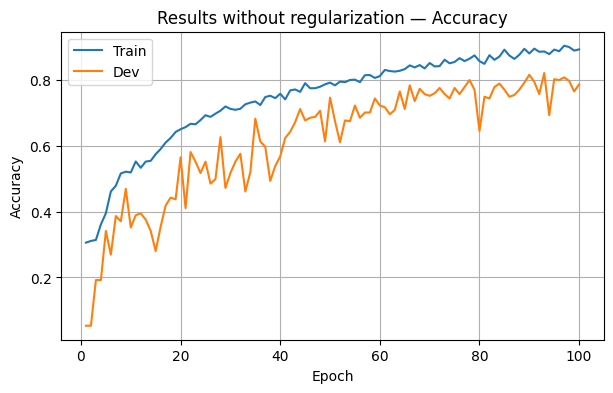

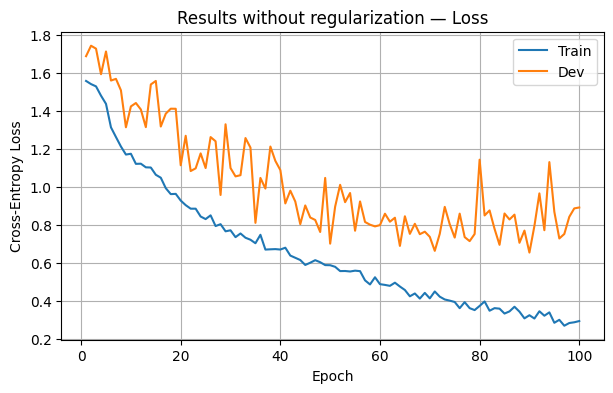

In [121]:
plot_results(train_acc, train_loss, dev_acc, dev_loss, "Results without regularization")

In [127]:
train_accR, train_lossR, dev_accR, dev_lossR = train(model_regularization, 150)

epoch  0  has finished. | Train Acc:  0.2975206611570248  | Dev Acc:  0.05333333333333334
epoch  1  has finished. | Train Acc:  0.3256714876033058  | Dev Acc:  0.08
epoch  2  has finished. | Train Acc:  0.3730888429752066  | Dev Acc:  0.37066666666666664
epoch  3  has finished. | Train Acc:  0.4371900826446281  | Dev Acc:  0.22133333333333333
epoch  4  has finished. | Train Acc:  0.46379132231404957  | Dev Acc:  0.144
epoch  5  has finished. | Train Acc:  0.4951962809917355  | Dev Acc:  0.42133333333333334
epoch  6  has finished. | Train Acc:  0.4826446280991736  | Dev Acc:  0.288
epoch  7  has finished. | Train Acc:  0.48326446280991736  | Dev Acc:  0.38133333333333336
epoch  8  has finished. | Train Acc:  0.5184400826446282  | Dev Acc:  0.288
epoch  9  has finished. | Train Acc:  0.5026342975206611  | Dev Acc:  0.208
epoch  10  has finished. | Train Acc:  0.5173553719008265  | Dev Acc:  0.2773333333333333
epoch  11  has finished. | Train Acc:  0.525  | Dev Acc:  0.3546666666666667
ep

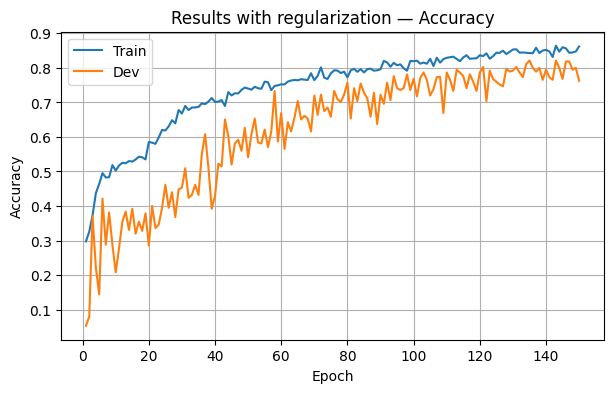

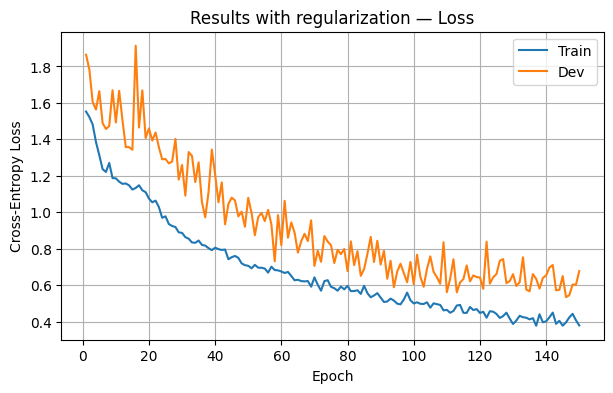

In [128]:
plot_results(train_accR, train_lossR, dev_accR, dev_lossR, "Results with regularization")